# Your Own Data: LAS, formations, lithology and diagnostics

Start with LAS alone, then add only the geology you actually have. This self-contained notebook uses bundled data and writes temporary demonstration CSV/TSV/Excel files; it does not modify package datasets.

**Beginner path:** sections 1-3. **Advanced path:** column/sheet/well mapping, depth metadata, explicit terminal depths, source selection and error handling in sections 4-8.

These are narrow tabular exchange profiles, not a universal industry format or a WITSML/PDF/mixture importer. See the [input guide](../docs/input_templates.md) for templates and industry-source references.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
from pathlib import Path
from tempfile import TemporaryDirectory
import numpy as np
import pandas as pd
import petrophys as pp
from IPython.display import display

scratch = TemporaryDirectory(prefix="petrophys-notebook-")
workdir = Path(scratch.name)

## 1. LAS alone is sufficient for a first plot

Replace the sample path with your own LAS path. Plotting does not require formations, lithology, Rw, or a completed interpretation. Verify the well identity and depth unit first.

30/6-5 176.60999 3556.08032 m


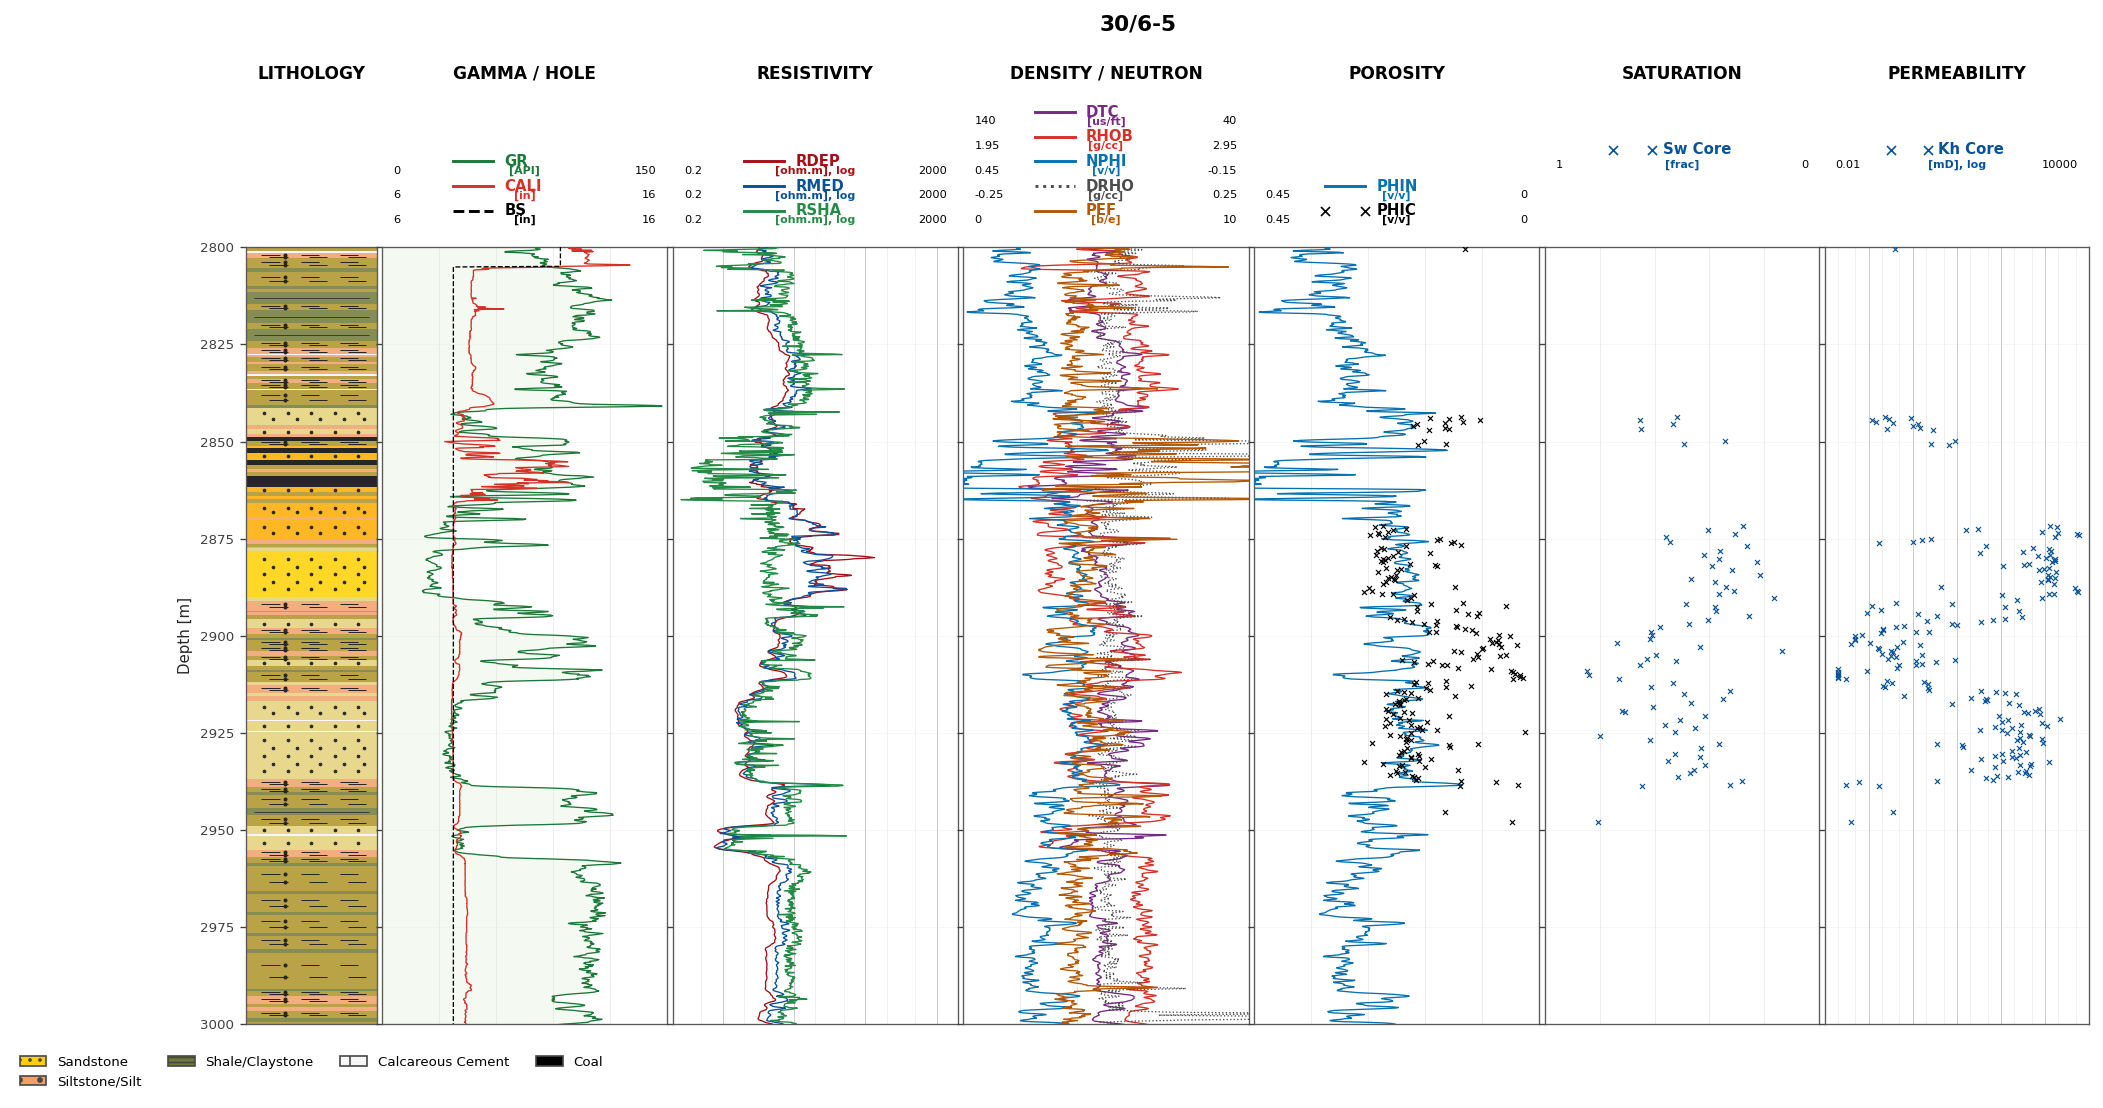

["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]


In [2]:
raw = pp.read(pp.sample("30_6-5"))
print(raw.name, raw.top, raw.bottom, raw.depth_unit)
viewer = pp.plot(raw, depth_range=(2800, 3000), figsize=(16, 9))
viewer.show()
viewer.close()
print(viewer.warnings)

**About the two `UserWarning` messages above.** They are a real data problem in the bundled LAS, not an error in your code: its core saturation curves `SWC` and `SOC` are labelled `frac` but hold percentages. Petrophys infers the percent scale, divides by 100 on a copy, and asks you to verify the source units (section 7 shows the stored evidence and how to declare units explicitly). Expect the same warning whenever this well is plotted or interpreted, so the next cell hides only this message. Your own files may raise different warnings; read them.

In [3]:
import warnings

# Already explained: the bundled 30/6-5 SWC/SOC curves hold percentages despite
# a 'frac' label. Hide only this message; every other warning stays visible.
warnings.filterwarnings(
    "ignore", message=r"(SWC|SOC): inferred percent core saturation", category=UserWarning,
)

## 2. Inspect the templates before filling them

Formation **tops** are point picks; formation **intervals** include actual bottoms. Lithology intervals require top, bottom and a rock label. All template rows below are **synthetic**, not interpretations of the bundled well.

Use CSV UTF-8 with one header row and numeric depth cells. Optional metadata can identify the well, length unit, depth reference and datum. Gaps in lithology remain gaps; overlaps and reversed intervals are rejected.

In [4]:
for name in ("formation_tops_template", "formation_intervals_template",
             "lithology_intervals_template", "lithology_codes_template"):
    print(name)
    display(pd.read_csv(pp.sample(name)))

formation_tops_template


,formation_name,top_depth
0,Formation_A,1000.0
1,Formation_B,1050.0
2,Formation_C,1120.0


formation_intervals_template


,formation_name,top_depth,bottom_depth
0,Formation_A,1000.0,1050.0
1,Formation_B,1050.0,1120.0
2,Formation_C,1120.0,1200.0


lithology_intervals_template


,top,bottom,lithology
0,1000.0,1025.0,Shale
1,1025.0,1050.0,Sandstone
2,1050.0,1120.0,Limestone
3,1120.0,1200.0,Shale


lithology_codes_template


,code,lithology
0,1,Sandstone
1,2,Shale
2,3,Limestone


## 3. Attach either or both optional geology tables

For a reproducible real-well example, use the bundled 30/6-5 companions, not the synthetic templates. Remove either keyword when that information is unavailable. Attached external lithology takes precedence in the default workflow; passing intervals only to a plot does not change interpretation inputs.

The bundled CSVs do not declare a depth reference or datum, so the diagnostics report that both were *assumed* to match the well. Section 4 shows how to declare them on both sides.

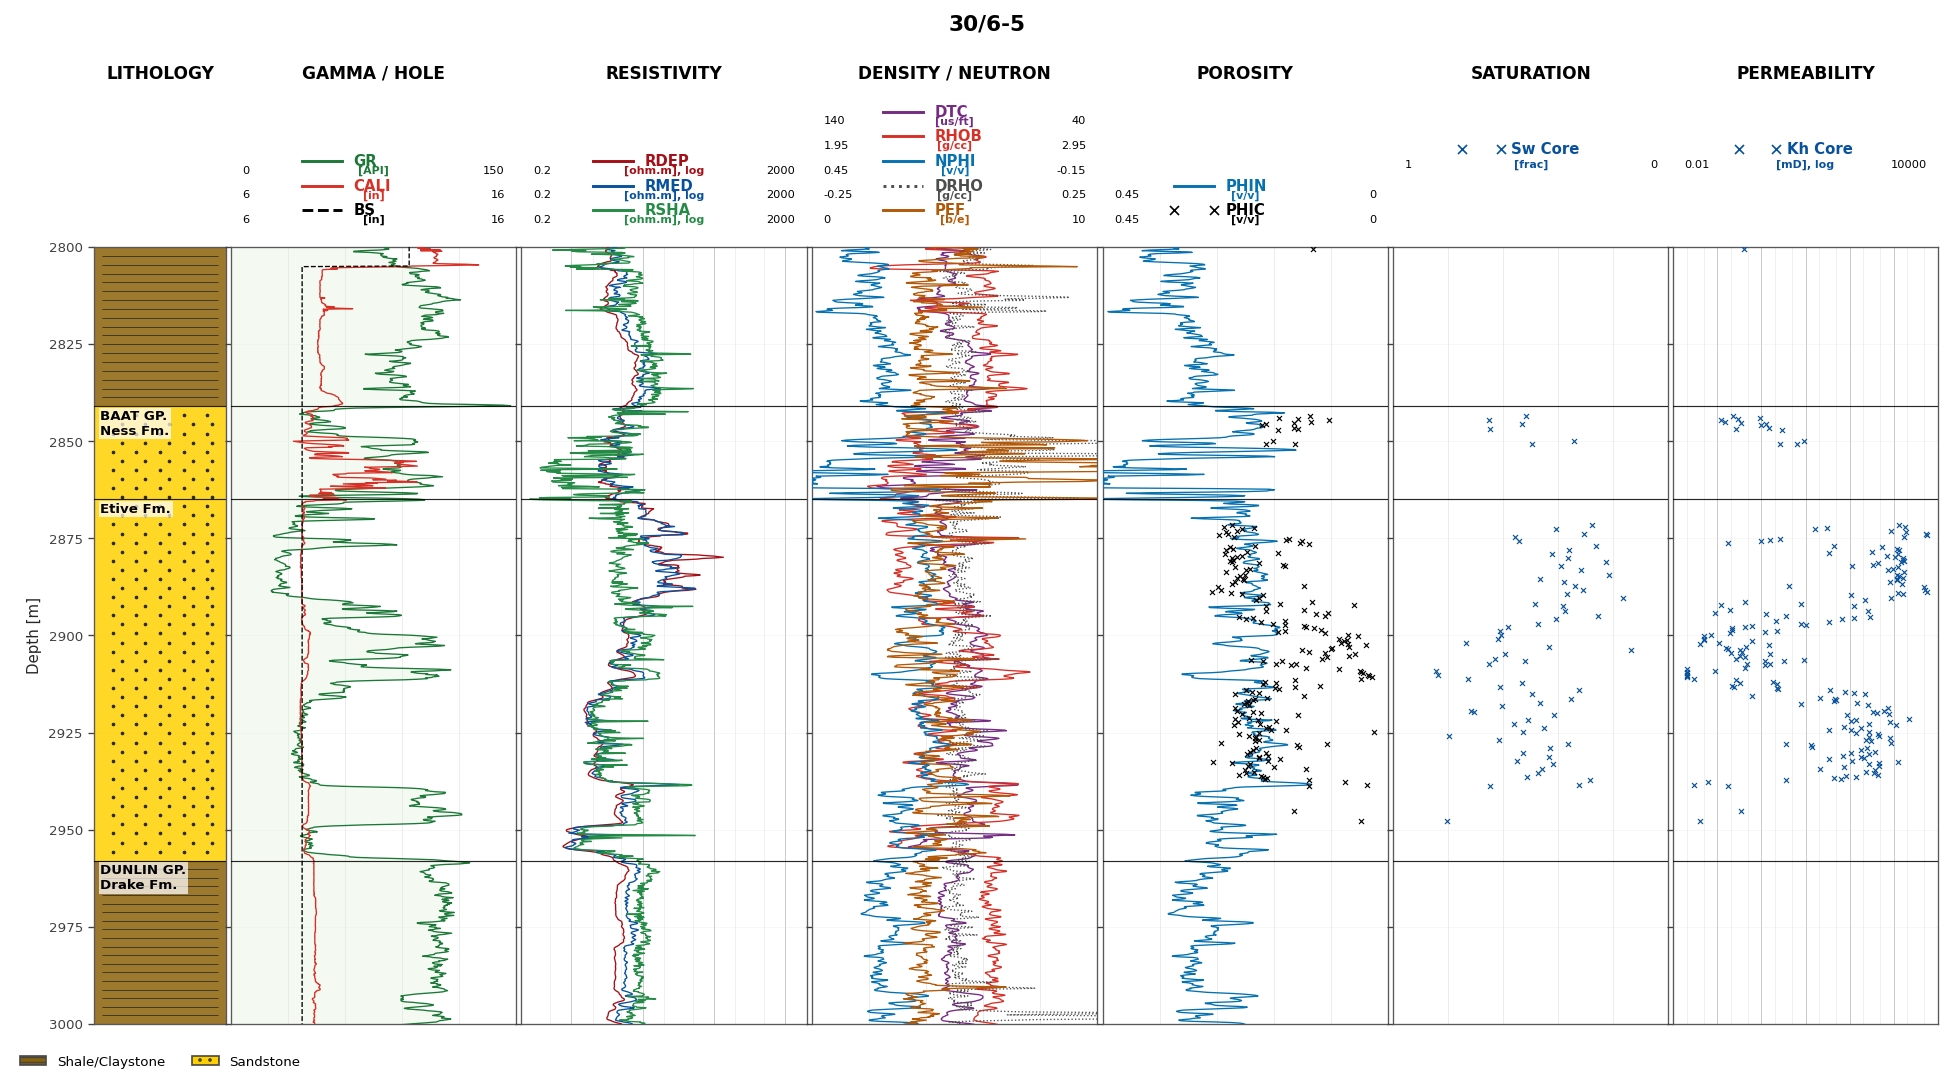

Lithology source: external
formations: 20 of 20 rows accepted
lithology: 13 of 13 rows accepted
Warnings:
  - No geology depth_reference supplied; assumed to match the well (not independently verified).
  - No geology datum supplied; assumed to match the well (not independently verified).
  - SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.


In [5]:
well = pp.read(
    pp.sample("30_6-5"),
    formations=pp.sample("formations_30_6-5"),
    lithology=pp.sample("lithology_30_6-5"),
)
viewer = pp.plot(well, depth_range=(2800, 3000), figsize=(16, 9))
viewer.show()
viewer.close()

diagnostics = viewer.diagnostics
print("Lithology source:", diagnostics["lithology_source"])
for table in ("formations", "lithology"):
    report = diagnostics[table]
    print(f"{table}: {report['accepted_rows']} of {report['input_rows']} rows accepted")
print("Warnings:")
for message in dict.fromkeys(viewer.warnings):  # each distinct message once
    print("  -", message)

## 4. Map real-world table layouts explicitly

A supplier may export one Excel workbook with several sheets and wells. The following is a **constructed vendor-layout example**, using two known tops from this well plus one deliberately unrelated well.

The source column names differ from the template, and depths are expressed in feet. We declare MD and RKB on both sides of the join for this example. In a real delivery, confirm those declarations with the source data; setting metadata is not a survey or datum transformation.

Column mappings run from canonical field name to source header. Select both the intended worksheet and well. The importer reports filtered rows and compatible unit conversions.

In [6]:
reference_well = pp.read(pp.sample("30_6-5"), depth_reference="MD", datum="RKB")
supplier = pd.DataFrame({
    "Well ID": ["30/6-5", "30/6-5", "OTHER-WELL"],
    "Marker": ["Ness Fm.", "Etive Fm.", "Unrelated"],
    "Pick feet": np.array([2841.0, 2865.0, 1000.0]) / 0.3048,
})
xlsx = workdir / "supplier_tops.xlsx"
with pd.ExcelWriter(xlsx) as writer:
    supplier.to_excel(writer, sheet_name="Tops", index=False)
    pd.DataFrame({"note": ["Demonstration workbook"]}).to_excel(writer, sheet_name="Notes", index=False)

mapping = {"well": "Well ID", "formation_name": "Marker", "top_depth": "Pick feet"}
tops = pp.read_formations(
    xlsx, sheet_name="Tops", well=reference_well, columns=mapping,
    depth_unit="ft", depth_reference="MD", datum="RKB",
)
np.testing.assert_allclose(tops.top_depth, [2841.0, 2865.0])
assert tops.attrs["import_report"]["filtered_rows"] == 1
display(tops)
display(tops.attrs["import_report"])

,formation_name,top_depth,well,rank
0,Ness Fm.,2841.0,30/6-5,formation
1,Etive Fm.,2865.0,30/6-5,formation


{'input_rows': 3,
 'accepted_rows': 2,
 'filtered_rows': 1,
 'well': '30/6-5',
 'column_mapping': {'Marker': 'formation_name',
  'Pick feet': 'top_depth',
  'Well ID': 'well'},
 'ignored_columns': [],
 'diagnostics': ['Stratigraphic rank inferred from name suffixes (GP./Fm./Mb.): formation.'],
 'depth_conversion': {'from': 'ft', 'to': 'm', 'factor': 0.3048}}

### Semicolon text and detailed lithology names

This example reformats the bundled lithology table, retaining its original rock names. An explicit mapping allows vendor comment columns to be omitted; the import report lists them. Numeric vendor codes must first be decoded with a verified codebook, not guessed to use the GeoLink scheme.

In [7]:
original_lithology = pp.read_lithology_intervals(pp.sample("lithology_30_6-5"))
supplier_lithology = original_lithology.rename(
    columns={"top": "From MD", "bottom": "To MD", "lithology": "Rock"}
)
supplier_lithology["Comment"] = "Demonstration export"
text_path = workdir / "supplier_lithology.txt"
supplier_lithology.to_csv(text_path, sep=";", index=False)
lithology = pp.read_lithology_intervals(
    text_path, sep=";", well=reference_well,
    columns={"top": "From MD", "bottom": "To MD", "lithology": "Rock"},
    depth_unit="m", depth_reference="MD", datum="RKB",
)
assert lithology.lithology.tolist() == original_lithology.lithology.tolist()
display(lithology.head())
display(lithology.attrs["import_report"])

,top,bottom,lithology
0,181.0,726.0,shale
1,726.0,879.0,sandstone
2,879.0,1908.0,shale
3,1908.0,2023.0,sandstone
4,2023.0,2203.0,shale


{'input_rows': 13,
 'accepted_rows': 13,
 'filtered_rows': 0,
 'well': None,
 'column_mapping': {'From MD': 'top', 'To MD': 'bottom', 'Rock': 'lithology'},
 'ignored_columns': ['Comment'],
 'diagnostics': []}

### CSV and TSV well logs

Tabular log files need an explicit depth column and unit. The two files below contain a small excerpt of the LAS, not a second independent well. This does not transfer the LAS's full header or interpretation metadata. DLIS uses `pp.read` too, with the optional `dlis` dependency; borehole images have their own specialist reader.

In [8]:
excerpt = pd.DataFrame({"MD": raw.depth[:20], "GR": raw["GR"].data[:20]})
for suffix, sep in ((".csv", ","), (".tsv", "\t")):
    path = workdir / ("log_excerpt" + suffix)
    excerpt.to_csv(path, index=False, sep=sep)
    imported = pp.read(path, depth_column="MD", depth_unit=raw.depth_unit)
    np.testing.assert_allclose(imported.depth, excerpt.MD)
    print(suffix, imported.n_samples, imported.depth_unit)

.csv 20 m
.tsv 20 m


## 5. Distinguish picks from bounded intervals

The viewer can draw `tops` directly without inventing bottoms. Analysis needs bounded intervals. Supply an actual terminal boundary, here 2958 m for the example Ness/Etive interval. There is no automatic '+100 units' final formation.

Mixed ranks or coincident tops need explicit bottoms or rank selection before deriving intervals. The formation summary API aggregates the covered depth union; do not sum overlapping group/member rows yourself.

In [9]:
from petrophys.model import FormationTops

bounded = FormationTops.from_dataframe(tops, terminal_depth=2958.0)
display(bounded.to_dataframe())
assert bounded.intervals[-1].bottom_depth == 2958.0
print("Rank and nested-total examples are in lesson 11.")

,name,top_depth,bottom_depth,thickness,kind,lithology,age,rank,well,depth_unit,depth_reference,datum
0,Ness Fm.,2841.0,2865.0,24.0,formation,,,formation,30/6-5,m,MD,RKB
1,Etive Fm.,2865.0,2958.0,93.0,formation,,,formation,30/6-5,m,MD,RKB


Rank and nested-total examples are in lesson 11.


## 6. Interpret with explicit assumptions and source selection

`Rw = 0.07 ohm.m` **measured at 230 degF** below is a teaching assumption for this well. Always pass the measurement temperature with `rw_meas_temp_f`; without it Petrophys takes Rw at the mean formation temperature (no temperature correction), which changes water saturation substantially. Review the fluid, temperature, matrix and cutoff choices before interpreting another well.

The default source policy is external intervals, then a recognized vendor log, then computed lithology. Alternatives are `lithology_source="vendor"`, `"computed"` or `"config"`; config requires explicit matrix/lithology choices. Missing explicitly requested inputs fail.

No external geology is required for the normal workflow. The mineral solver runs only when supported by its logs. See lesson 05 for the no-geology solver route.

In [10]:
curves_before = tuple(well.curves)
result = pp.interpret(well, rw=0.07, rw_meas_temp_f=230)
result.raise_for_errors()
assert result.well is not well
assert tuple(well.curves) == curves_before

context_step = next(step for step in result.steps_executed if step.step == "input_context")
context = context_step.parameters
assert context["selected_source"] == "external"
print("Status:", result.status)
print("Lithology source requested / selected:",
      context["requested_source"], "/", context["selected_source"])
print("Samples covered / not covered by external lithology:",
      context["covered_samples"], "/", context["uncovered_samples"])
print("Attached formations used:", context["formations"]["used"])
print("Skipped steps:")
for step, reason in result.specific_steps_skipped.items():
    print(f"  {step}: {reason}")
print("Warnings:")
for message in result.warnings:
    print("  -", message)

Status: interpreted
Lithology source requested / selected: auto / external
Samples covered / not covered by external lithology: 22146 / 30
Attached formations used: True
Skipped steps:
  normalization: standardize_input=False
  spectral_gamma: Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_spectral_gamma directly
  elemental_spectroscopy: Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_elemental_spectroscopy directly
  hc_correction: apply_hc_correction=False (hydrocarbon correction is opt-in)
  porosity_refinement: Not run by the interpretation workflow; porosity is computed once in the porosity step
Warnings:
  - Marl uses the limestone matrix and carbonate cutoff family. This is a routing convention, not a calibrated marl model; check clay correction and supply project-specific cutoffs.
  - External lithology: unmapped labels [], 30 uncovered samples. Labels/gaps are preserved; unclassified samp

### Results per formation

Attached formations also organize the answer. `result.formation_summary(rank="formation")` reports gross, net and average properties for each formation. The bundled tops mix groups and formations, so choose one rank (`"formation"` or `"group"`) rather than adding overlapping rows yourself. The average columns are taken over net-pay samples only, so they are blank (`NaN`) where a formation has no pay.

Treat each row as a claim to check against the geology. With default cutoffs, intervals outside the reservoir, such as shallow, poorly consolidated sediments, can pass the porosity and saturation cutoffs. The reservoir in this well is the Brent Group: the Ness and Etive formations, 2841-2958 m.

In [11]:
by_formation = result.formation_summary(rank="formation")
columns = ["Formation", "Top", "Bottom", "Gross (m)", "Net Pay (m)", "Avg PHIE", "Avg Sw", "Avg VCL"]
by_formation[columns].round(2)

,Formation,Top,Bottom,Gross (m),Net Pay (m),Avg PHIE,Avg Sw,Avg VCL
0,Utsira Fm.,726.0,879.0,153.01,34.90,0.45,0.65,0.07
1,Balder Fm.,1908.0,2023.0,115.06,26.82,0.34,0.64,0.12
2,Sele Fm.,2023.0,2123.0,99.97,0.00,NaN,NaN,NaN
3,Lista Fm.,2123.0,2203.0,80.01,0.46,0.35,0.66,0.12
4,Draupne Fm.,2452.0,2593.0,140.97,0.00,NaN,NaN,NaN
5,Heather Fm.,2593.0,2841.0,247.95,0.76,0.26,0.66,0.00
6,Ness Fm.,2841.0,2865.0,24.08,6.71,0.18,0.67,0.11
7,Etive Fm.,2865.0,2958.0,92.96,31.09,0.22,0.31,0.03
8,Drake Fm.,2958.0,3071.0,113.08,0.00,NaN,NaN,NaN
9,Cook Fm.,3071.0,3123.0,51.97,3.20,0.17,0.65,0.21


## 7. Core saturation and calculated SW are different products

The workflow keeps core saturation in the units the LAS declares. In the bundled LAS the SWC values are percentages although the header says 'frac', so declare the unit yourself: `standardize_core_saturation(curve, source_unit="%")` converts percentages, and `source_unit="v/v"` confirms fractions. The conversion evidence is stored on the curve. Unknown scales cannot always be inferred. Neither a unit conversion nor a visual match establishes that core measurements equal in-situ log-derived saturation.

{'original_unit': 'frac',
 'source_unit': '%',
 'target_unit': 'v/v',
 'factor': 0.01,
 'reason': 'explicit_override',
 'masked_count': 0,
 'warnings': []}

Core fraction range: 0.137 - 0.846


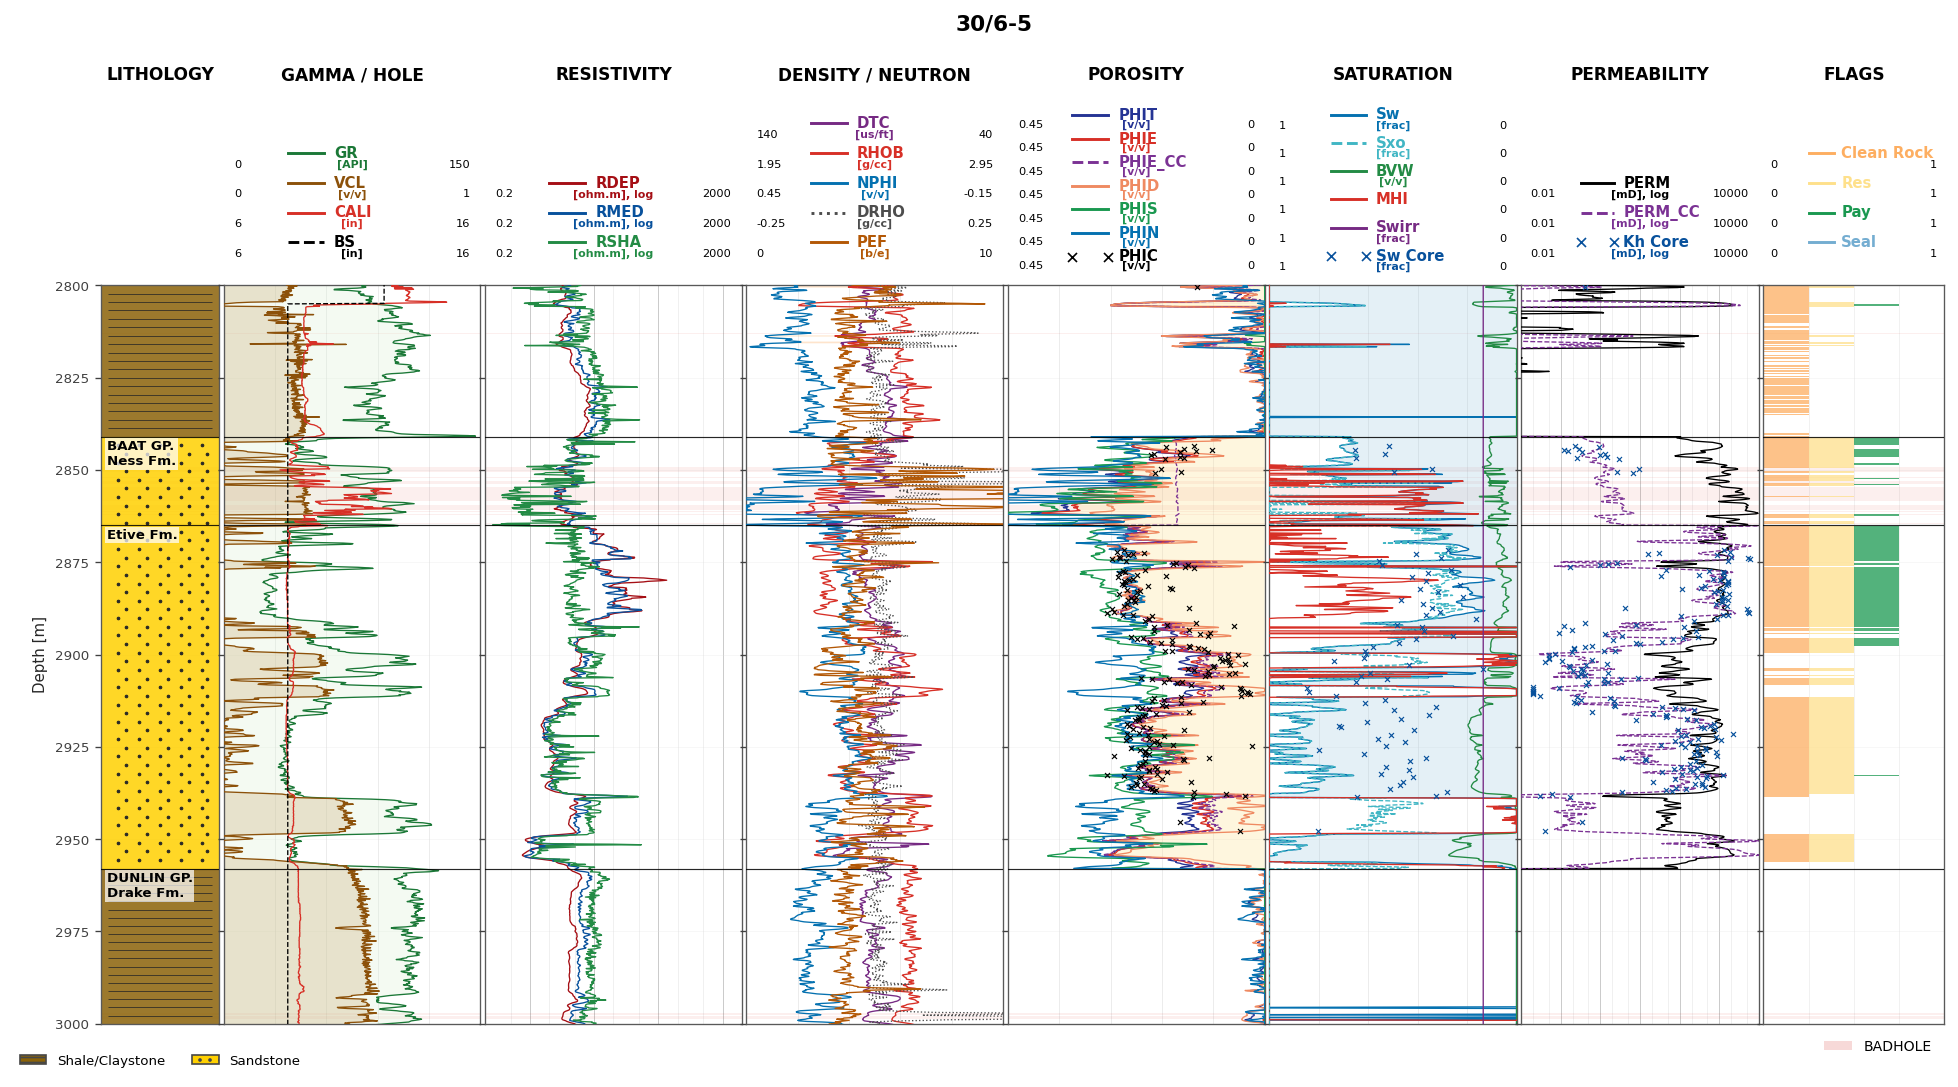

In [12]:
from petrophys.preprocessing import standardize_core_saturation

core = result.well.get("SWC")
if core is not None:
    core = standardize_core_saturation(core, source_unit="%")
    display(core.metadata.custom.get("core_saturation_normalization", {}))
    finite = core.data[np.isfinite(core.data)]
    assert np.all((finite >= 0) & (finite <= 1))
    print(f"Core fraction range: {finite.min():.3f} - {finite.max():.3f}")

viewer = result.plot(depth_range=(2800, 3000), figsize=(16, 9))
viewer.show()
viewer.close()

## 8. Diagnose input problems before trusting a plot

The examples below deliberately fail and check the actual errors. They are not skipped cells. Notice that a sheet choice is required and a TVDSS-to-MD join is rejected, even when the numeric depths overlap.

Missing depth metadata is recorded as an assumption. Numeric overlap alone is not evidence of correct physical alignment.

In [13]:
def show_expected_error(label, action):
    try:
        action()
    except (ValueError, FileNotFoundError) as exc:
        print(label + ":", exc)
    else:
        raise AssertionError("Expected validation error: " + label)

show_expected_error("Missing file", lambda: pp.read_formations("missing_tops.csv"))
show_expected_error("Choose a sheet", lambda: pp.read_formations(xlsx, columns=mapping))
show_expected_error(
    "Reference mismatch",
    lambda: pp.read_formations(
        supplier.iloc[:2], columns=mapping, well=reference_well,
        depth_unit="ft", depth_reference="TVDSS", datum="RKB",
    ),
)
show_expected_error(
    "Overlapping lithology",
    lambda: pp.read_lithology_intervals(pd.DataFrame({
        "top": [1000, 1050], "bottom": [1100, 1150], "lithology": ["Sandstone", "Shale"],
    })),
)

Missing file: Geology input not found: missing_tops.csv
Choose a sheet: Select sheet_name explicitly; workbook sheets: ['Tops', 'Notes']
Reference mismatch: Incompatible depth_reference: geology=TVDSS, well=MD; a survey/datum transformation is required.
Overlapping lithology: Lithology row 3: overlapping intervals; provide one categorical lithology per depth. Mixtures require separate data.


## Save an output and keep the trace

Use `viewer.save` for figures, `result.to_las` for the interpreted curves (the LAS header records the settings used and the executed and skipped steps), and `result.to_json` for the complete machine-readable trace. This demonstration writes inside its temporary directory and then removes those temporary files. For a real project, choose your own output directory and retain source files, import metadata and assumptions.

In [14]:
import json

export_viewer = result.plot(depth_range=(2800, 3000), figsize=(16, 9))
figure_path = workdir / "interpretation.png"
export_viewer.save(figure_path)
export_viewer.close()
las_path = result.to_las(workdir / "interpreted.las")
trace_path = result.to_json(workdir / "workflow_trace.json")

assert figure_path.stat().st_size > 0
assert pp.read(las_path).has_curve("SW")
assert json.loads(trace_path.read_text(encoding="utf-8"))["status"] == result.status
print("Exported and verified:", figure_path.name, las_path.name, trace_path.name)
scratch.cleanup()

Exported and verified: interpretation.png interpreted.las workflow_trace.json


## Next steps

- [Quickstart](quickstart.ipynb): the shortest read/plot/interpret route.
- [QA/QC](part_a_foundations/02_qaqc_and_standardization.ipynb): core unit overrides and provenance.
- [Workflow](part_b_advanced/10_dynamic_workflow_glass_box.ipynb): advanced configuration and traces.
- [Formation analysis](part_b_advanced/11_formation_and_interval_analysis.ipynb): hierarchy, explicit bottoms and union totals.
- [Visualization](part_b_advanced/17_visualization_masterclass.ipynb): track selection and specialist figures.

**Exercise:** remove both geology arguments from section 3 and rerun. Then add only formations, then only lithology. Compare the plot diagnostics and the `input_context` step rather than assuming every run selected the same source.